=== Baseline Metrics ===
Initial Connected Defect Components: 5
Initial Total Defect Area: 1147037 pixels



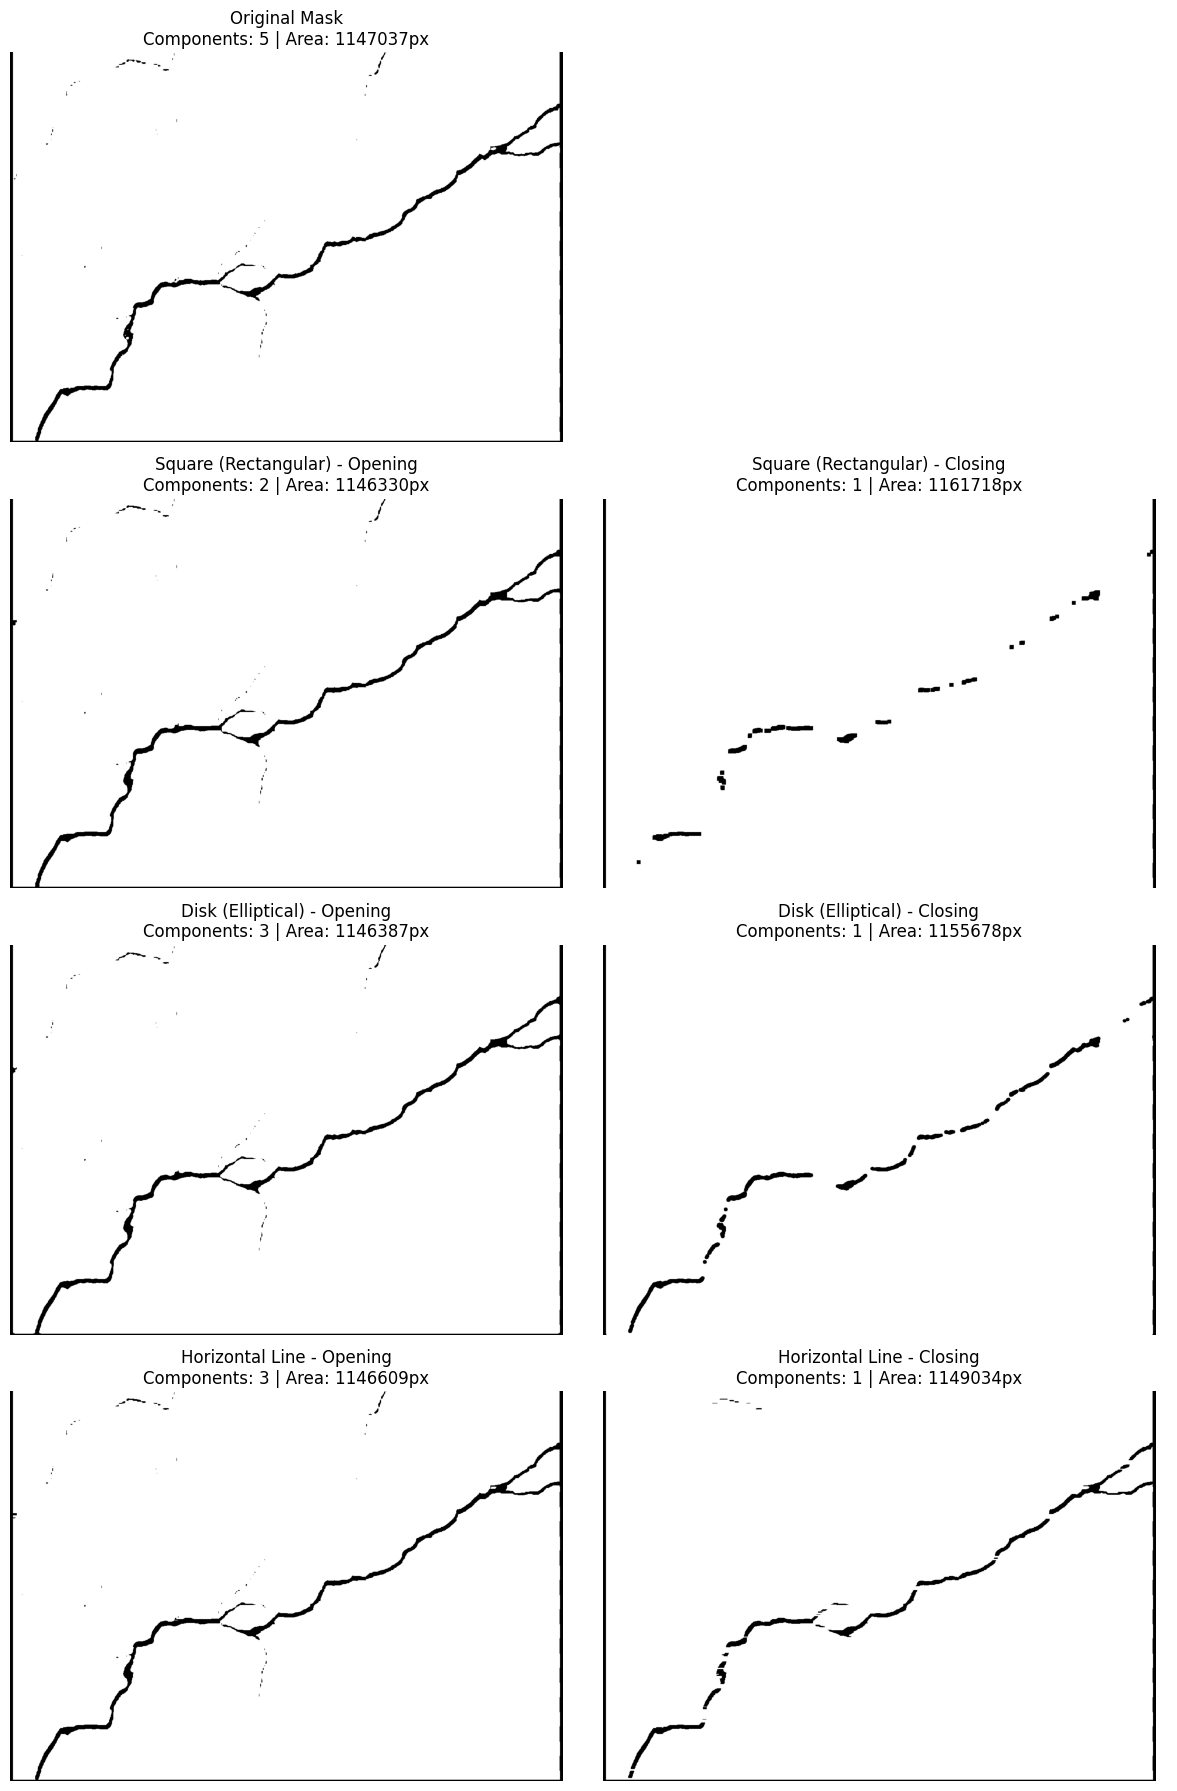

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a synthetic industrial defect mask
def generate_defect_mask():
    # 300x300 canvas
    mask = np.zeros((300, 300), dtype=np.uint8)
    
    # Structural Component 1: A rounded/curved defect profile
    cv2.circle(mask, (80, 150), 35, 255, -1)
    
    # Structural Component 2: A fragmented straight line defect (with small gap)
    cv2.line(mask, (160, 80), (220, 80), 255, 6)
    cv2.line(mask, (235, 80), (280, 80), 255, 6)
    
    # Add unwanted fine background noise
    np.random.seed(10)
    noise_x = np.random.randint(0, 300, 40)
    noise_y = np.random.randint(0, 300, 40)
    mask[noise_y, noise_x] = 255
    
    return mask

# Try to load local image 'defect_surface.png' or fallback to synthetic mask
gray_img = cv2.imread('building.png', cv2.IMREAD_GRAYSCALE)
if gray_img is None:
    print("Local image 'defect_surface.png' not found. Generating a synthetic defect mask...")
    binary_mask = generate_defect_mask()
else:
    _, binary_mask = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)

# %%
# 2. Metric Evaluation Function
def calculate_metrics(img_mask):
    # connectedComponentsWithStats returns: num_labels, labels_matrix, stats, centroids
    num_labels, _, stats, _ = cv2.connectedComponentsWithStats(img_mask)
    
    # num_labels includes the background layer (label 0), subtract 1 for actual defects
    num_defects = num_labels - 1
    
    # Sum the areas of all components except the background (index 0)
    total_area = np.sum(stats[1:, cv2.CC_STAT_AREA]) if num_defects > 0 else 0
    return num_defects, total_area

# Calculate baseline stats
initial_count, initial_area = calculate_metrics(binary_mask)
print(f"=== Baseline Metrics ===")
print(f"Initial Connected Defect Components: {initial_count}")
print(f"Initial Total Defect Area: {initial_area} pixels\n")

# %%
# 3. Define Structuring Elements (Kernel Size: 9x9)
k_size = 9
structuring_elements = {
    "Square (Rectangular)": cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size)),
    "Disk (Elliptical)": cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size)),
    "Horizontal Line": cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, 1))
}

# Run experiments and hold frames
results = {}
for name, se in structuring_elements.items():
    opened = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, se)
    closed = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, se)
    
    open_count, open_area = calculate_metrics(opened)
    close_count, close_area = calculate_metrics(closed)
    
    results[name] = {
        "opened": opened, "open_count": open_count, "open_area": open_area,
        "closed": closed, "close_count": close_count, "close_area": close_area
    }

# %%
# 4. Display Results and Comparisons
fig, axes = plt.subplots(4, 2, figsize=(12, 18))

# Row 0: Original Mask Reference
axes[0, 0].imshow(binary_mask, cmap='gray')
axes[0, 0].set_title(f"Original Mask\nComponents: {initial_count} | Area: {initial_area}px")
axes[0, 0].axis('off')
axes[0, 1].axis('off') # Leave empty next to original

# Rows 1-3: Morphological shapes
for idx, (name, res) in enumerate(results.items(), start=1):
    # Column 1: Opening
    axes[idx, 0].imshow(res["opened"], cmap='gray')
    axes[idx, 0].set_title(f"{name} - Opening\nComponents: {res['open_count']} | Area: {res['open_area']}px")
    axes[idx, 0].axis('off')
    
    # Column 2: Closing
    axes[idx, 1].imshow(res["closed"], cmap='gray')
    axes[idx, 1].set_title(f"{name} - Closing\nComponents: {res['close_count']} | Area: {res['close_area']}px")
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

